# 02 · Cross-modal task and bias correction

The cross-modal task compares an auditory test with a 500 ms visual standard. Let A* be the auditory PSE; the visual correction used in the main experiment is 0.5 − A* seconds, added to every visual flash (`VisualPSE`).

The launcher computes the correction automatically, with the same code as below (`avdur.bias`), and asks for confirmation. This notebook re-fits the correction, compares it with v1's linear method, and checks that every main-experiment block used the confirmed values.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().resolve().parent                      # av_dur_experiment_v2/
sys.path[:0] = [str(ROOT), str(ROOT.parent)]            # experiment code + repository (plot_style.py)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from plot_style import *                            # shared figure style of the repository
except ImportError:
    FONT_SIZE_LABEL, FONT_SIZE_TITLE = 14, 16
    def add_panel_labels(*a, **k): pass

import experiment_settings as S
from avdur import storage, psychometrics as pm, bias as bias_mod

DATA_ROOT = ROOT / 'data'
if not storage.participants(DATA_ROOT):
    DATA_ROOT = ROOT / 'data_simulated'
    print('No real participants in data/ yet: showing SIMULATED participants (python tests/test_pipeline.py).')
print('Data folder:', DATA_ROOT, '| participants:', storage.participants(DATA_ROOT))

No real participants in data/ yet: showing SIMULATED participants (python tests/test_pipeline.py).
Data folder: /Users/ofy204/Documents/my_repos/av-dur-estimation/av_dur_experiment_v2/data_simulated | participants: ['SIM01', 'SIM02']


In [2]:
def binned(df, x_col='x', n_bins=8):
    d = df.copy()
    d['bin'] = pd.qcut(d[x_col], n_bins, duplicates='drop')
    return d.groupby('bin', observed=True).agg(x=(x_col, 'mean'), p=('chose_test', 'mean'), n=('chose_test', 'size'))

def order_balance(df, keys):
    t = df.groupby(keys + ['order']).size().unstack(fill_value=0)
    t['test-second share'] = (t.get(2, 0) / t.sum(axis=1)).round(2)
    return t

In [3]:
xm = storage.load_trials('crossmodal', root=DATA_ROOT)
print(f'{len(xm)} cross-modal trials')
runs = xm.sort_values(['session_file', 'trial_num']).groupby('session_file').order.apply(
    lambda s: (s != s.shift()).cumsum().value_counts().value_counts().to_dict())
print('order mini-block sizes per session ({size: count}):'); print(runs.to_string())
display(order_balance(xm, ['participantID', 'audNoise']))

776 cross-modal trials
order mini-block sizes per session ({size: count}):
session_file                            
SIM01_crossmodal_20261019-154059.csv  10    38
                                      4      2
SIM02_crossmodal_20261019-154109.csv  10    38
                                      4      2


order                    1   2  test-second share
participantID audNoise                           
SIM01         0.1       97  97                0.5
              1.2       97  97                0.5
SIM02         0.1       97  97                0.5
              1.2       97  97                0.5

## Bias correction per participant

In [4]:
rows, estimates = [], {}
for pid in sorted(xm.participantID.unique()):
    est = bias_mod.estimate_for_participant(pid, DATA_ROOT, n_boot=100)
    estimates[pid] = est
    for noise, e in sorted(est['per_noise'].items()):
        rows.append(dict(participant=pid, noise=float(noise), correction_s=e['correction_s'],
                         ci95_low=e['ci95_s'][0], ci95_high=e['ci95_s'][1],
                         v1_method_s=est['comparison_linear_v1'][noise], pse_auditory_s=e['pse_auditory_s'],
                         sigma=e['sigma'], lapse=e['lapse'], warnings='; '.join(est['warnings'])))
corrections = pd.DataFrame(rows)
corrections.round(3)

,participant,noise,correction_s,ci95_low,ci95_high,v1_method_s,pse_auditory_s,sigma,lapse,warnings
0,SIM01,0.1,0.100,0.071,0.127,0.090,0.400,0.367,0.0,
1,SIM01,1.2,-0.020,-0.057,0.012,-0.033,0.520,0.339,0.0,
2,SIM02,0.1,-0.102,-0.131,-0.075,-0.108,0.602,0.255,0.0,
3,SIM02,1.2,0.165,0.137,0.189,0.156,0.335,0.451,0.0,


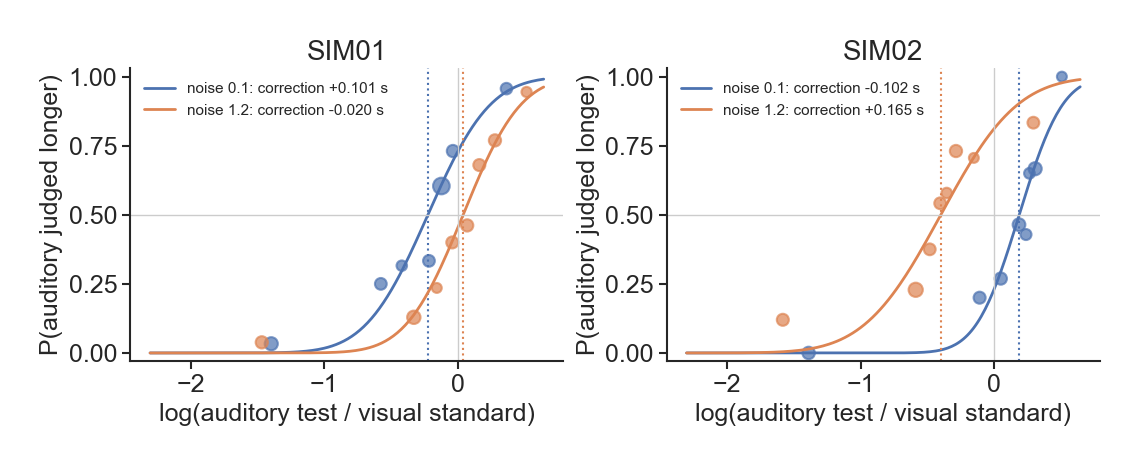

In [5]:
pids = sorted(xm.participantID.unique())
fig, axes = plt.subplots(1, len(pids), figsize=(5.5 * len(pids), 4.4), squeeze=False)
for ax, pid in zip(axes[0], pids):
    d = xm[xm.participantID == pid].copy()
    d['x'] = np.log(d.testDurS / d.standardDur)
    fit = pm.fit(d, 'audNoise', 'lognormal', lapse_max=S.BIAS['lapse_max'])['params'].set_index('condition')
    xs = np.linspace(d.x.min(), d.x.max(), 200)
    for k, noise in enumerate(S.NOISE_LEVELS):
        color = sns.color_palette('deep')[k]
        b = binned(d[d.audNoise == noise])
        ax.scatter(b.x, b.p, s=b.n * 3, color=color, alpha=0.7)
        f = fit.loc[noise]
        corr = estimates[pid]['per_noise'][str(noise)]['correction_s']
        ax.plot(xs, pm.predict(xs, f.mu, f.sigma, f.lapse), color=color, label=f'noise {noise}: correction {corr:+.3f} s')
        ax.axvline(f.mu, color=color, ls=':', lw=1.5)
    ax.axhline(0.5, color='0.8', lw=1); ax.axvline(0, color='0.8', lw=1)
    ax.set(title=pid, xlabel='log(auditory test / visual standard)', ylabel='P(auditory judged longer)', ylim=(-0.03, 1.03))
    ax.legend(fontsize=11, frameon=False, loc='upper left')
    sns.despine(ax=ax)
fig.tight_layout()
plt.show()

## Corrections actually used in the main experiment

In [6]:
used = []
for meta in storage.sessions(task='main', root=DATA_ROOT):
    for noise, applied in meta['corrections_applied_s'].items():
        used.append(dict(participant=meta['participant'], block=meta['block'], noise=float(noise), applied_s=applied,
                         bias_file=Path(meta['bias_file']).name if meta.get('bias_file') else None))
used = pd.DataFrame(used)
if len(used):
    check = used.merge(corrections[['participant', 'noise', 'correction_s']], on=['participant', 'noise'], how='left')
    check['difference_ms'] = 1000 * (check.applied_s - check.correction_s)     # rounding to frames: within +-4.2 ms
    display(check.round(4))
    print('One bias file per participant:', used.groupby('participant').bias_file.nunique().eq(1).all())
else:
    print('No main-experiment sessions yet.')

,participant,block,noise,applied_s,bias_file,correction_s,difference_ms
0,SIM01,B1,0.1,0.1000,SIM01_bias_20261019-154109.json,0.1005,-0.5000
1,SIM01,B1,1.2,-0.0167,SIM01_bias_20261019-154109.json,-0.0201,3.4333
2,SIM01,B2,0.1,0.1000,SIM01_bias_20261019-154109.json,0.1005,-0.5000
3,SIM01,B2,1.2,-0.0167,SIM01_bias_20261019-154109.json,-0.0201,3.4333
4,SIM01,B3,0.1,0.1000,SIM01_bias_20261019-154109.json,0.1005,-0.5000
5,SIM01,B3,1.2,-0.0167,SIM01_bias_20261019-154109.json,-0.0201,3.4333
6,SIM02,B1,0.1,-0.1000,SIM02_bias_20261019-154121.json,-0.1021,2.1000
7,SIM02,B1,1.2,0.1667,SIM02_bias_20261019-154121.json,0.1651,1.5667
8,SIM02,B2,0.1,-0.1000,SIM02_bias_20261019-154121.json,-0.1021,2.1000
9,SIM02,B2,1.2,0.1667,SIM02_bias_20261019-154121.json,0.1651,1.5667


One bias file per participant: True


## Timing check

In [7]:
x = xm.copy()
x['standard_error_ms'] = 1000 * (x.recordedDurVisualStandard - x.intendedDurVisualStandard)
x.groupby(['participantID', 'order'])[['standard_error_ms', 'n_dropped_frames']].agg(['median', 'max']).round(1)

standard_error_ms      n_dropped_frames    
                               median  max           median max
participantID order                                            
SIM01         1                   0.0  1.0              0.0   0
              2                  -0.0  1.0              0.0   0
SIM02         1                  -0.0  1.1              0.0   0
              2                   0.0  0.9              0.0   0